<a href="https://colab.research.google.com/github/diegocortes30/pharma_batch_quality_analysis/blob/main/04_analysis_pharma.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Pharma Batch Quality Analysis: 04 Analysis**


**Goal:** answer the four business questions using control charts (I-MR) and Spearman correlations, and translate the results into recommendations for the Quality department.

**Input:** `data/processed/pharma_clean.csv` (output of notebook 03).

**Output:** 14 charts in `reports/figures/` (I-MR charts, correlation heatmaps and a before/after correlation comparison).

**Data:** [Big data collection in pharmaceutical manufacturing](https://figshare.com/collections/Cholessterol-Lowering_Drug_Process_and_Quality_Data/5645578) (figshare), 3 CSV files: Laboratory, Process, Normalization.

**Source:** Žagar, J. & Mihelič, J. (2022). Big data collection in pharmaceutical manufacturing and its use for product quality predictions. Scientific Data, 9(1), 99. https://doi.org/10.1038/s41597-022-01203-x

**Contents:** setup and data loading, business questions (Q1-Q4), summary of findings.

## 1. Setup and data loading

In [26]:
from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROCESSED = '/content/drive/MyDrive/pharma_batch_quality_analysis/data/processed'
FIGURES = '/content/drive/MyDrive/pharma_batch_quality_analysis/reports/figures'
os.makedirs(FIGURES, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [27]:
pharma = pd.read_csv('/content/drive/MyDrive/pharma_batch_quality_analysis/data/processed/pharma_clean.csv',
                          parse_dates=['start'])

In [28]:
# Check the shape
pharma.shape

(1005, 78)

In [29]:
# Check the dtype of start
pharma.dtypes.head()

,0
batch,int64
code,int64
strength,int64
size,int64
start,datetime64[ns]


In [30]:
# Order by start and batch
pharma = pharma.sort_values(by=['start', 'batch']).reset_index(drop=True)

## 2. Business questions

### *Q1: How stable is the process over time and across products in terms of minimum dissolution and total impurities?*

In [31]:
# Variability summary per dose
summary = pharma.groupby('strength')[['dissolution_min', 'impurities_total']].agg(['mean', 'std'])
summary

dissolution_min           impurities_total          
                    mean       std             mean       std
strength                                                     
5              89.200803  3.509181         0.125020  0.090652
10             85.751174  3.608044         0.126995  0.100181
20             84.110112  3.587894         0.165798  0.101489
40             82.775510  3.891653         0.077755  0.056778

In [32]:
# Add RSD (std/mean * 100) to the table
summary[('dissolution_min', 'rsd')] = summary[('dissolution_min', 'std')] / summary[('dissolution_min', 'mean')] * 100
summary[('impurities_total', 'rsd')] = summary[('impurities_total', 'std')] / summary[('impurities_total', 'mean')] * 100
summary = summary.sort_index(axis=1).round(2)
summary

dissolution_min             impurities_total             
                    mean   rsd   std             mean    rsd   std
strength                                                          
5                  89.20  3.93  3.51             0.13  72.51  0.09
10                 85.75  4.21  3.61             0.13  78.89  0.10
20                 84.11  4.27  3.59             0.17  61.21  0.10
40                 82.78  4.70  3.89             0.08  73.02  0.06

In [33]:
# Create function to build the next plots
def plot_imr(df, variable, group, ylabel, group_col='strength'):
    """Plot an I-MR chart for one variable and one group (dose, API source, etc.),
    save it and return out-of-control counts."""
    data = df[df[group_col] == group].reset_index(drop=True)
    values = data[variable]
    mr = values.diff().abs()

    center = values.mean()
    mr_bar = mr.mean()
    ucl_i = center + 2.66 * mr_bar
    lcl_i = max(center - 2.66 * mr_bar, 0)   # values cannot be negative
    ucl_mr = 3.267 * mr_bar

    fig, (ax_i, ax_mr) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

    ax_i.plot(values.index, values, marker='o', markersize=3, linewidth=0.8)
    ax_i.axhline(center, color='green', label=f'Center = {center:.2f}')
    ax_i.axhline(ucl_i, color='red', linestyle='--', label=f'UCL = {ucl_i:.2f}')
    ax_i.axhline(lcl_i, color='red', linestyle='--', label=f'LCL = {lcl_i:.2f}')
    ax_i.set_ylabel(ylabel)
    ax_i.set_title(f'I-MR chart: {variable}, {group_col} = {group}')
    ax_i.legend(loc='upper right', fontsize=8)

    ax_mr.plot(mr.index, mr, marker='o', markersize=3, linewidth=0.8)
    ax_mr.axhline(mr_bar, color='green', label=f'MR bar = {mr_bar:.2f}')
    ax_mr.axhline(ucl_mr, color='red', linestyle='--', label=f'UCL = {ucl_mr:.2f}')
    ax_mr.set_ylabel('Moving range')
    ax_mr.set_xlabel('Batch order (within group)')
    ax_mr.legend(loc='upper right', fontsize=8)

    plt.tight_layout()
    plt.savefig(f'{FIGURES}/imr_{variable}_{group_col}_{group}.png', dpi=150, bbox_inches='tight')
    plt.show()

    return {'variable': variable, 'group_col': group_col, 'group': group, 'batches': len(values),
            'above_ucl': (values > ucl_i).sum(), 'below_lcl': (values < lcl_i).sum()}

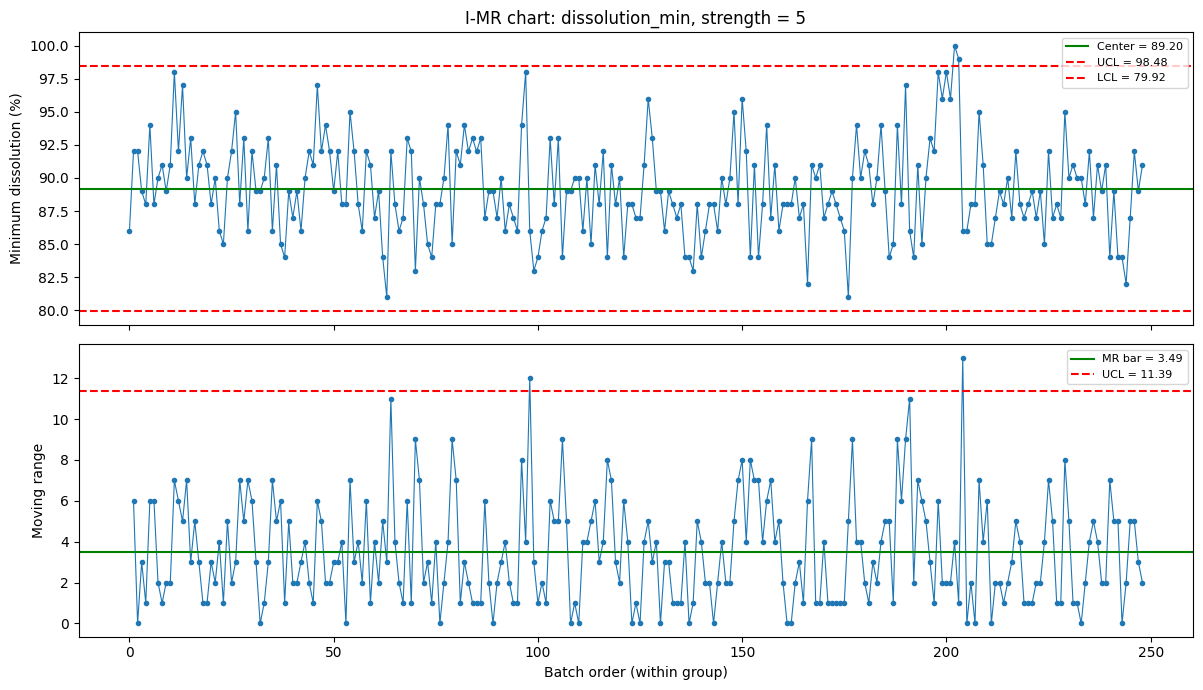

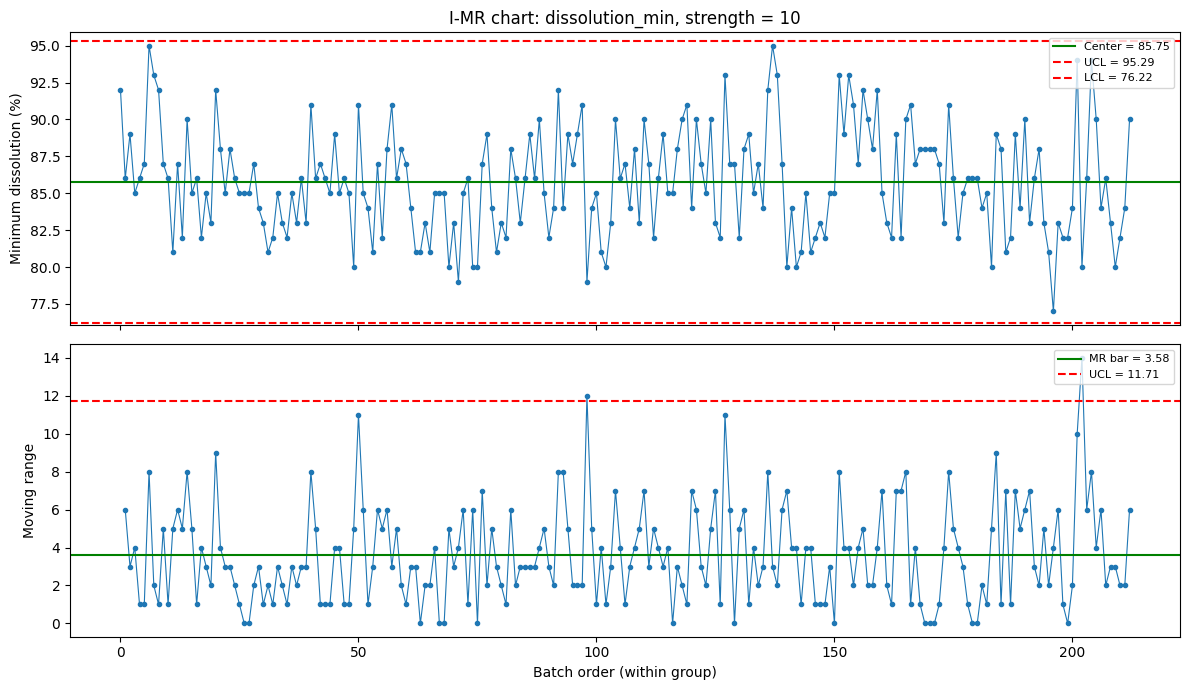

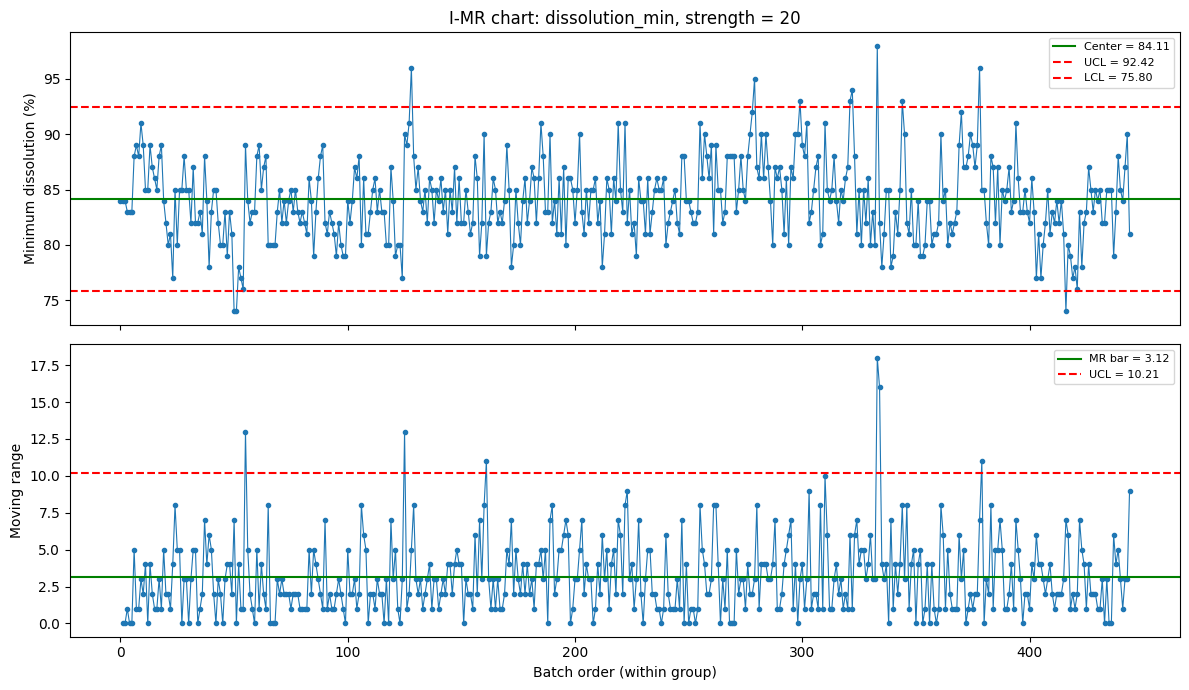

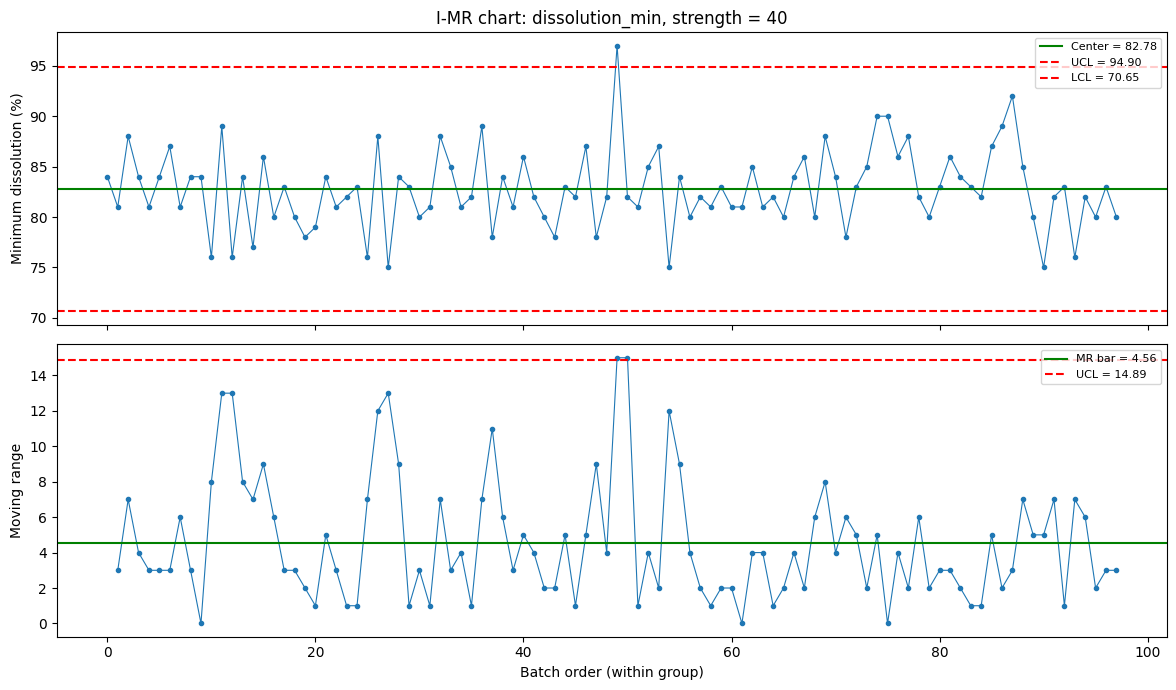

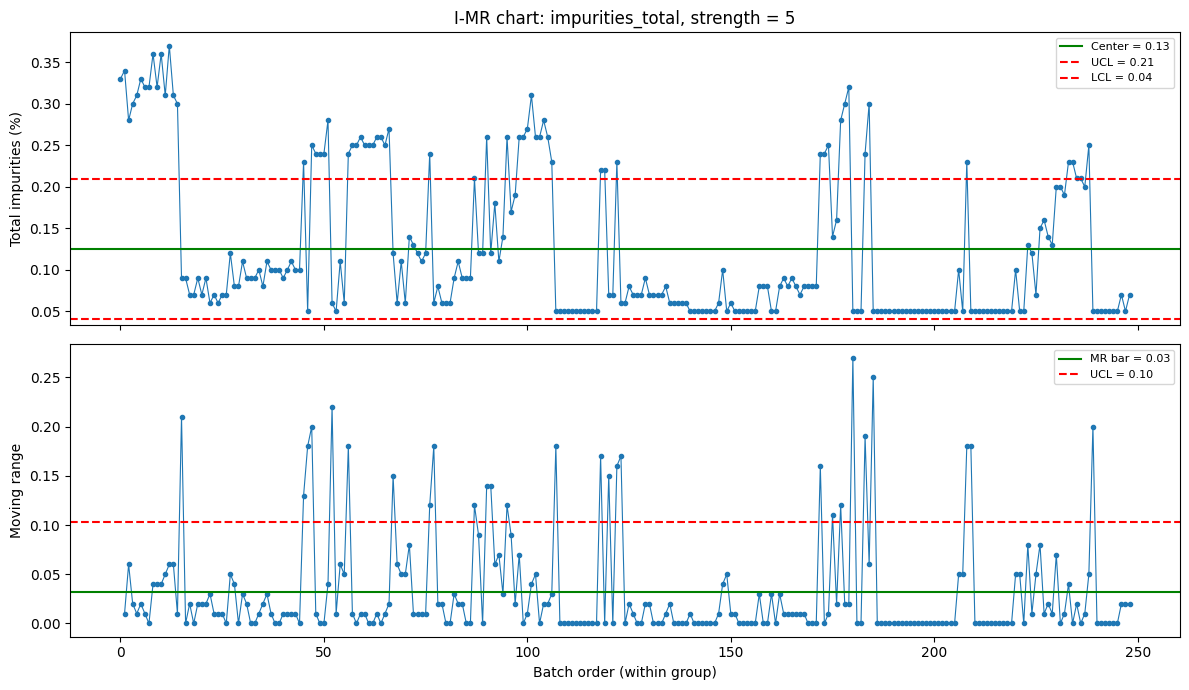

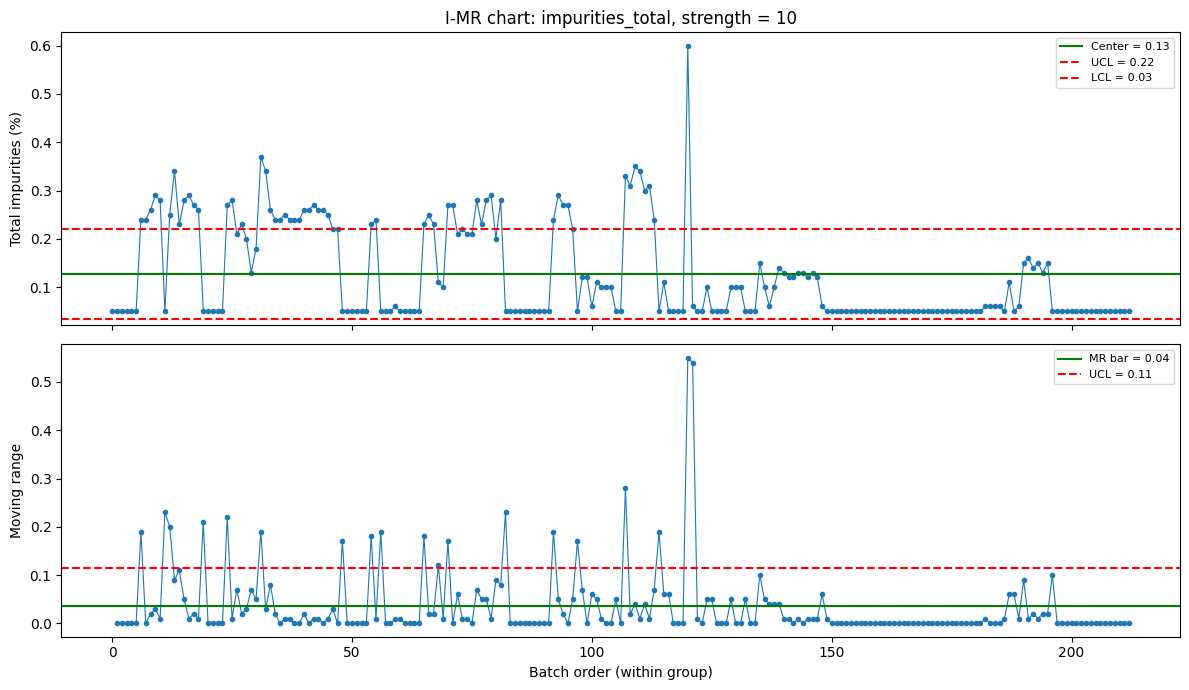

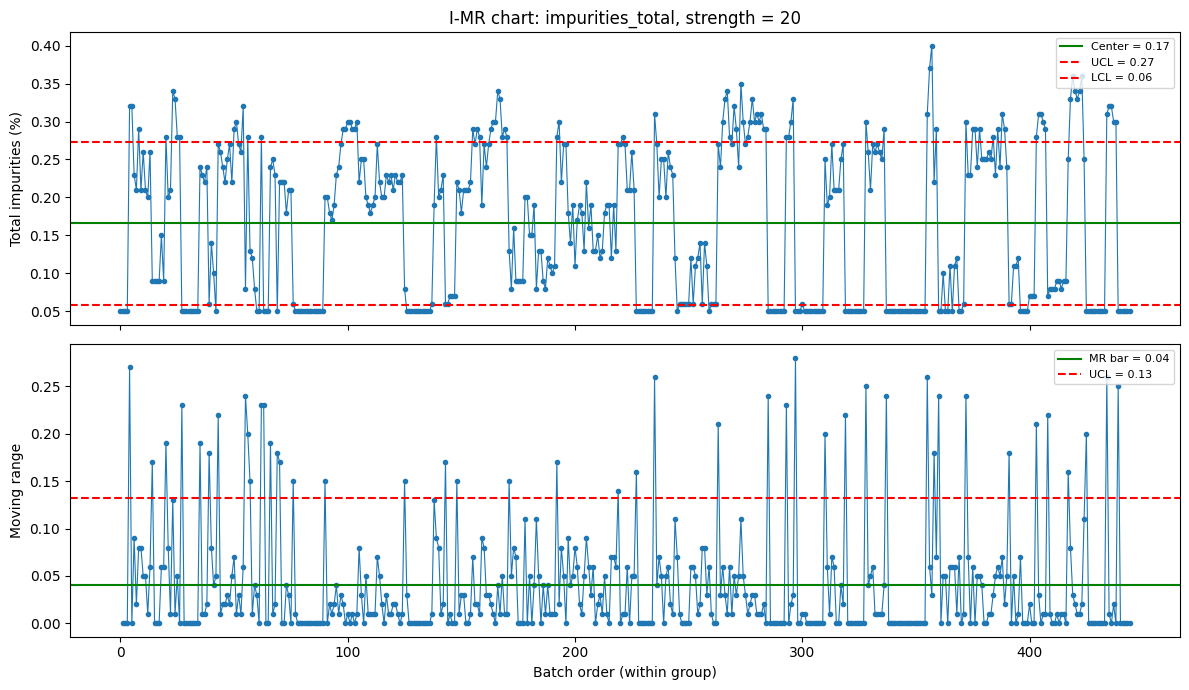

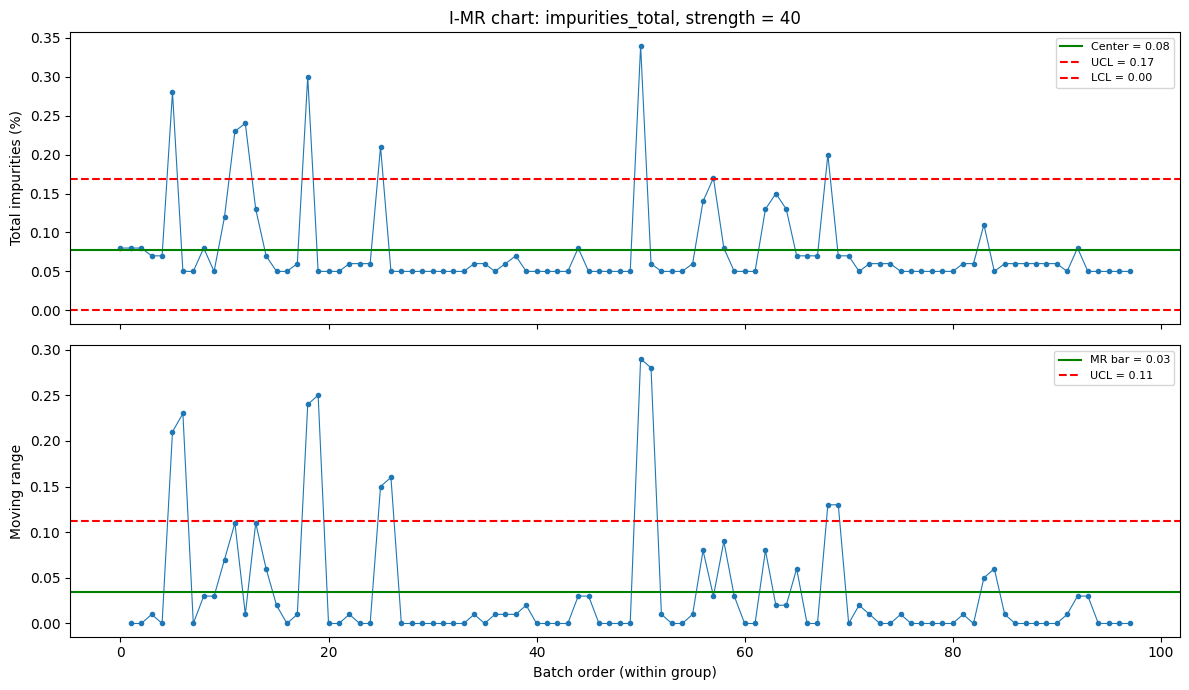

In [34]:
# I-MR charts for both quality variables and all doses
variables = {'dissolution_min': 'Minimum dissolution (%)',
             'impurities_total': 'Total impurities (%)'}
doses = sorted(pharma['strength'].unique())

results = []
for variable, ylabel in variables.items():
    for dose in doses:
        results.append(plot_imr(pharma, variable, dose, ylabel))

In [35]:
# Out-of-control summary
control_summary = pd.DataFrame(results)
control_summary['out_of_control_pct'] = ((control_summary['above_ucl'] + control_summary['below_lcl'])
                                         / control_summary['batches'] * 100).round(2)
control_summary

,variable,group_col,group,batches,above_ucl,below_lcl,out_of_control_pct
0,dissolution_min,strength,5,249,2,0,0.80
1,dissolution_min,strength,10,213,0,0,0.00
2,dissolution_min,strength,20,445,8,3,2.47
3,dissolution_min,strength,40,98,1,0,1.02
4,impurities_total,strength,5,249,62,0,24.90
5,impurities_total,strength,10,213,54,0,25.35
6,impurities_total,strength,20,445,87,126,47.87
7,impurities_total,strength,40,98,8,0,8.16


**Total impurities by API source**

The dose charts for total impurities show level shifts (steps) instead of random variation, and the out-of-control percentage follows the share of API source 5 in each dose (e.g. 48% of 20 mg batches use source 5 → 47.87% out of control). This indicates that impurities depend mainly on the API source, so dose charts mix different populations. Impurities are therefore analyzed by API source. Sources 2 (15 batches) and 4 (24 batches) are excluded because they have too few batches for a reliable chart.

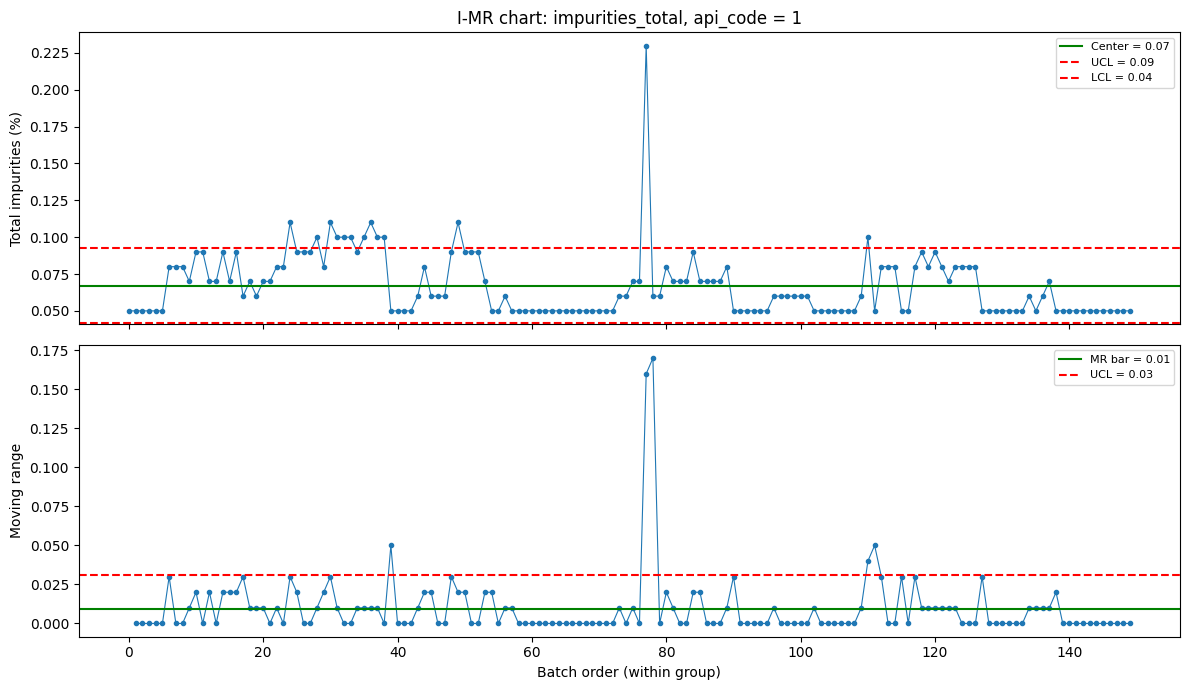

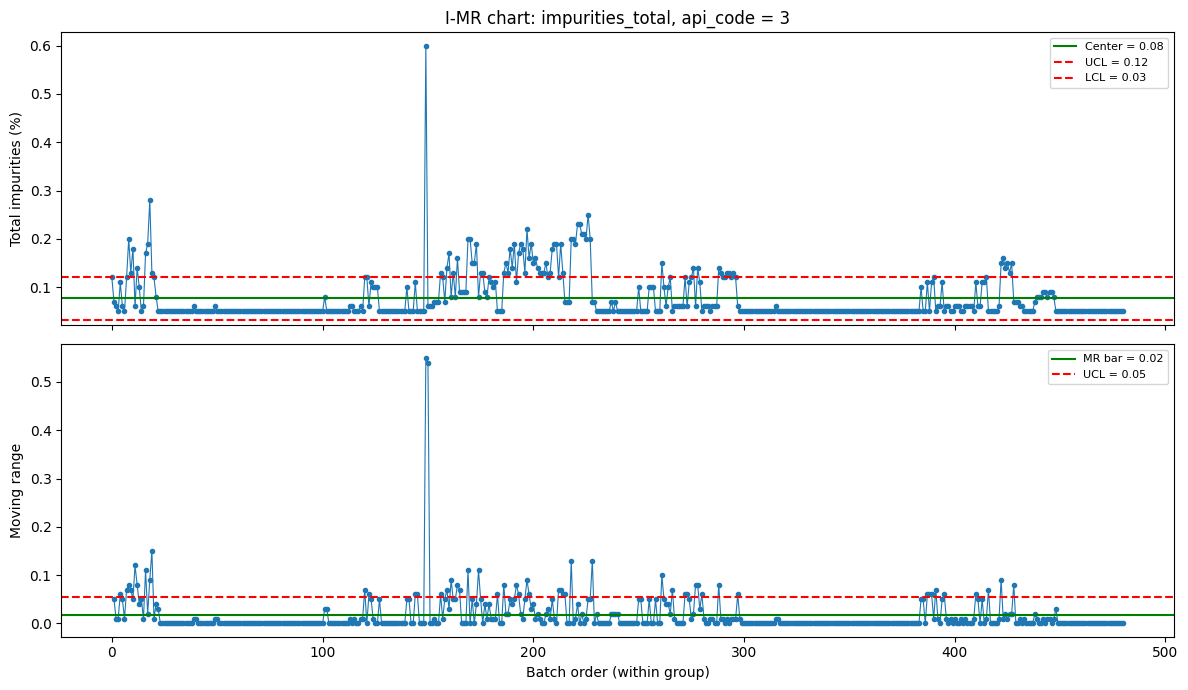

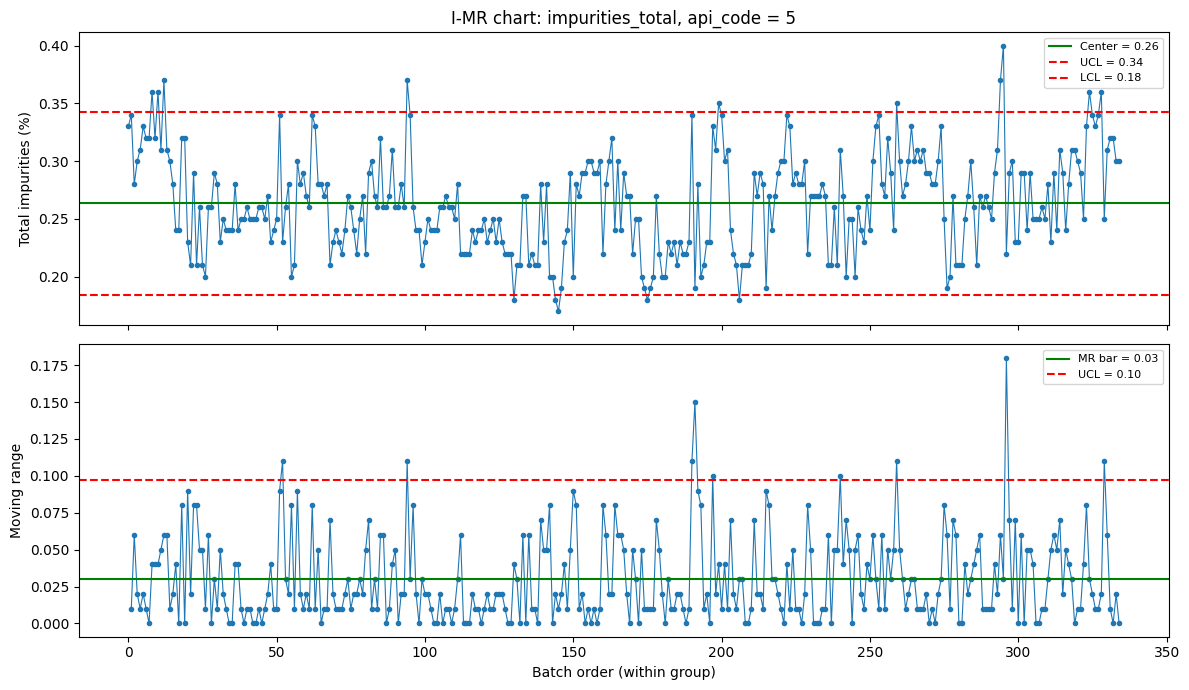

In [36]:
# I-MR charts for total impurities per API source (sources with enough batches)
api_sources = [1, 3, 5]

results_api = []
for source in api_sources:
    results_api.append(plot_imr(pharma, 'impurities_total', source, 'Total impurities (%)',
                                group_col='api_code'))

In [37]:
# Out-of-control summary per API source
api_control_summary = pd.DataFrame(results_api)
api_control_summary['out_of_control_pct'] = ((api_control_summary['above_ucl'] + api_control_summary['below_lcl'])
                                             / api_control_summary['batches'] * 100).round(2)
api_control_summary

,variable,group_col,group,batches,above_ucl,below_lcl,out_of_control_pct
0,impurities_total,api_code,1,150,13,0,8.67
1,impurities_total,api_code,3,481,71,0,14.76
2,impurities_total,api_code,5,335,10,5,4.48


**Findings:**

1. **Minimum dissolution:** the process is practically **in control** for 5, 10 and 40 mg (0–1% of batches out of control). **20 mg is the least stable dose**: 2.47% of batches are out of control (about 9 times more than expected by chance with ±3σ limits), with a period at a higher level and a drop at the end. Only 3 batches of 20 mg fall below the LCL, which is the real quality risk.

2. **Variability increases with the dose:** the RSD of minimum dissolution goes from 3.93% (5 mg) to 4.70% (40 mg), and 40 mg also has the lowest average dissolution.

3. **Total impurities by dose:** the charts showed level shifts (steps) and 25–48% of batches out of control. The cause is the **mix of API sources**: the out-of-control percentage follows the share of API source 5 in each dose (e.g. 48% of 20 mg batches use source 5 → 47.87% out of control).

4. **Total impurities by API source:** source 5 behaves as a stable process (4.48% out of control) at a level **about 3 times higher** (~0.26%) than the other sources. Sources 1 and 3 are almost always at the quantification limit (0.05%), which makes the I-MR chart unreliable for them: many identical consecutive values produce very narrow control limits, so small increases appear as out of control.

5. **Limitations:**
- Process capability (Ppk) could not be calculated because specification limits are not reported in the article.
- Total impurities are not normally distributed (concentrated at the quantification limit), so their control limits should be interpreted with caution.
- Control limits are statistical limits, not specification limits: according to the article, all batches are within specification.

### *Q2: Which raw material characteristics (API content, water, impurities and particle size, and excipient properties) are most strongly related to minimum dissolution and total impurities?*

In [38]:
# Create two lists
inputs = ['api_water', 'api_total_impurities', 'api_l_impurity',
          'api_content', 'api_ps01', 'api_ps05', 'api_ps09',
          'lactose_water', 'lactose_sieve0045', 'lactose_sieve015',
          'lactose_sieve025', 'smcc_water', 'smcc_td', 'smcc_bd',
          'smcc_ps01', 'smcc_ps05', 'smcc_ps09', 'starch_ph', 'starch_water']

targets = ['dissolution_min', 'impurities_total']

**Method:** Spearman correlation is used because total impurities are not normally distributed (concentrated at the quantification limit). Correlations are calculated across all batches and then within API sources 5 and 3, to check whether relationships are real or only reflect the difference between suppliers.

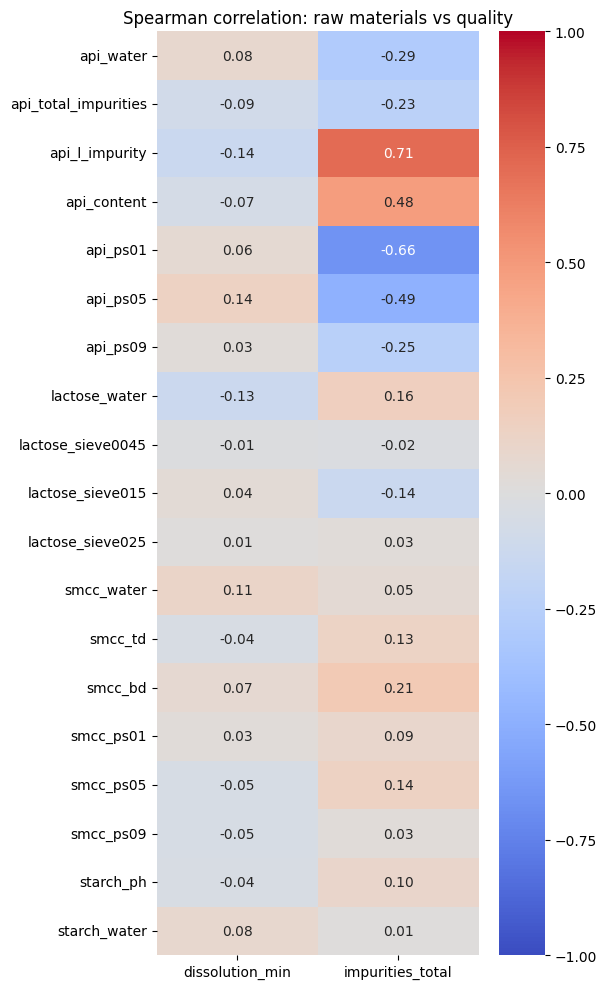

In [39]:
# Spearman correlation between raw materials and quality variables
corr_matrix = pharma[inputs + targets].corr(method='spearman')
corr_q2 = corr_matrix.loc[inputs, targets].round(2)

plt.figure(figsize=(6, 10))
sns.heatmap(corr_q2, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Spearman correlation: raw materials vs quality')
plt.tight_layout()
plt.savefig(f'{FIGURES}/q2_raw_materials_correlation.png', dpi=150, bbox_inches='tight')
plt.show()

In [40]:
# Spearman correlation within API source 5
source_5 = pharma[pharma['api_code'] == 5]
corr_source_5 = source_5[inputs + targets].corr(method='spearman').loc[inputs, targets].round(2)
corr_source_5

,dissolution_min,impurities_total
api_water,0.07,0.07
api_total_impurities,0.13,0.37
api_l_impurity,0.11,0.34
api_content,-0.08,-0.09
api_ps01,0.10,-0.20
api_ps05,0.05,-0.21
api_ps09,0.03,-0.26
lactose_water,-0.12,0.19
lactose_sieve0045,-0.03,-0.05
lactose_sieve015,-0.04,-0.11


In [41]:
# Spearman correlation within API source 3
source_3 = pharma[pharma['api_code'] == 3]
corr_source_3 = source_3[inputs + targets].corr(method='spearman').loc[inputs, targets].round(2)
corr_source_3

,dissolution_min,impurities_total
api_water,-0.07,-0.15
api_total_impurities,0.00,0.32
api_l_impurity,-0.00,0.56
api_content,0.03,0.11
api_ps01,0.08,-0.05
api_ps05,0.06,-0.03
api_ps09,-0.02,0.01
lactose_water,-0.13,-0.04
lactose_sieve0045,-0.02,0.02
lactose_sieve015,0.04,-0.15


**Findings:**

1. **Minimum dissolution:** no raw material characteristic is related to minimum dissolution (|ρ| ≤ 0.14), either across all batches or within each API source.

2. **Total impurities – API source effect:** the strong correlations with API particle size (`api_ps01` ρ = −0.66, `api_ps05` ρ = −0.49), API content (ρ = 0.48) and API water (ρ = −0.29) disappear within each API source. They reflected the difference between suppliers (mainly source 5), not a real effect of these characteristics.

3. **Total impurities – real relationships:** API L impurity (ρ = 0.34 in source 5, 0.56 in source 3) and API total impurities (ρ = 0.37 and 0.32) are related to total impurities in the final product **within each source**. This is chemically consistent: impurities in the API are carried over to the tablet.

4. **Simpson's paradox:** `api_total_impurities` shows a negative correlation across all batches (ρ = −0.23) but a positive one within each source (ρ = 0.32–0.37). Analyzing all batches together, without separating by supplier, leads to wrong conclusions.

5. **Limitations:**
- Correlation does not imply causation.
- `api_l_impurity` has few values in source 3 (~111 of 481 batches).
- The correlations with SMCC properties found in source 3 (e.g. `smcc_ps05` ρ = 0.33) are not confirmed in source 5, so they are treated as unconfirmed observations.

### *Q3: Are the compression parameters (main compression force, press speed, rejected tablets) related to minimum dissolution and total impurities?*

In [42]:
# Create two lists
compress_input = ['main_compforce_mean', 'main_compforce_sd', 'tbl_speed_mean',
                  'srel_production_mean', 'tbl_fill_mean', 'tbl_fill_sd',
                  'total_waste', 'startup_waste_norm', 'tbl_tensile', 'fct_tensile']

compress_target = ['dissolution_min', 'impurities_total']

**Method:** Spearman correlation across all batches and then within each dose, since compression force, fill depth and dissolution all change with the dose (notebook 02).

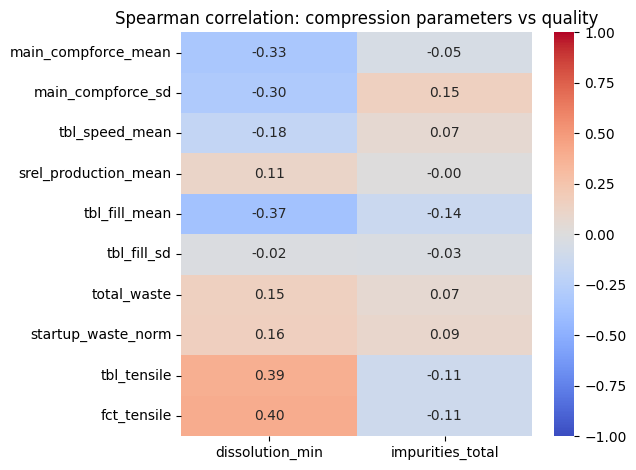

In [43]:
# Check the correlation
corr_matrix_c = pharma[compress_input + compress_target].corr(method='spearman')
corr_q3 = corr_matrix_c.loc[compress_input, compress_target].round(2)

sns.heatmap(corr_q3, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Spearman correlation: compression parameters vs quality')
plt.tight_layout()
plt.savefig(f'{FIGURES}/q3_compression_correlation.png', dpi=150, bbox_inches='tight')
plt.show()

In [44]:
# Spearman correlation within each dose
dissolution_by_dose = {}
impurities_by_dose = {}

for dose in sorted(pharma['strength'].unique()):
    corr_dose = pharma[pharma['strength'] == dose][compress_input + compress_target].corr(method='spearman')
    dissolution_by_dose[dose] = corr_dose.loc[compress_input, 'dissolution_min']
    impurities_by_dose[dose] = corr_dose.loc[compress_input, 'impurities_total']

corr_dissolution_dose = pd.DataFrame(dissolution_by_dose).round(2)
corr_impurities_dose = pd.DataFrame(impurities_by_dose).round(2)

corr_dissolution_dose

,5,10,20,40
main_compforce_mean,0.06,-0.07,0.17,-0.04
main_compforce_sd,0.10,0.01,0.11,-0.03
tbl_speed_mean,-0.07,-0.00,0.01,0.04
srel_production_mean,0.01,-0.01,0.08,0.07
tbl_fill_mean,-0.14,0.24,0.07,-0.05
tbl_fill_sd,-0.07,0.19,-0.03,0.14
total_waste,0.13,0.16,0.03,-0.06
startup_waste_norm,0.07,0.14,0.05,-0.04
tbl_tensile,0.15,0.01,0.03,0.05
fct_tensile,0.26,-0.19,0.02,0.08


In [45]:
corr_impurities_dose

,5,10,20,40
main_compforce_mean,-0.09,0.17,-0.24,-0.21
main_compforce_sd,-0.05,0.23,0.24,0.09
tbl_speed_mean,-0.01,-0.34,0.02,-0.11
srel_production_mean,0.19,0.07,-0.04,0.05
tbl_fill_mean,-0.35,-0.54,-0.23,-0.21
tbl_fill_sd,0.15,-0.18,0.00,-0.20
total_waste,-0.11,0.13,0.15,-0.11
startup_waste_norm,-0.12,0.09,0.17,-0.05
tbl_tensile,0.14,0.12,-0.08,0.03
fct_tensile,0.26,0.18,-0.33,-0.21


In [46]:
# Mean fill depth per dose and API source
pharma.groupby(['strength', 'api_code'])['tbl_fill_mean'].mean().unstack().round(2)

api_code,1,2,3,4,5
strength,,,,,
5,5.36,3.63,5.19,5.08,4.69
10,5.53,4.44,5.53,5.65,4.79
20,6.58,4.95,6.53,NaN,6.21
40,8.72,6.50,8.42,8.45,8.26


**Findings:**

1. **Dissolution (all batches):** compression force (ρ = −0.33), fill depth (ρ = −0.37) and tablet tensile strength (ρ = +0.40) seem to be related to minimum dissolution.

2. **Dissolution (within each dose):** these correlations disappear (|ρ| ≤ 0.26, with signs changing between doses). The overall correlation came from the dose: higher doses use more compression force and fill depth, and dissolve less. Compression parameters do not explain the variation in dissolution within the same product.

3. **Impurities:** compression parameters are not related to total impurities. The only consistent relationship, fill depth (ρ between −0.21 and −0.54 in all 4 doses), is explained by the API source: in all doses, source 5 batches have lower fill depth and higher impurities.

4. **Observation:** the API source also influences process settings (lower fill depth with source 5), probably because of differences in powder properties.

5. **Limitations:**
- Correlation does not imply causation.
- 40 mg has fewer batches (98).
- None of the measured variables explain the variation in dissolution within each dose.


### *Q4: Which input and process variables should be monitored by the Quality department to anticipate batches at risk of low dissolution or high impurities?*

This question summarizes the results of Q1–Q3. A variable is recommended for monitoring only if its relationship with quality is **consistent**: it must hold within each API source or dose, not only across all batches. Variables whose correlations disappear within groups are listed as *not recommended*, to show where monitoring resources should not be spent.

Fill depth is the only variable consistently related to impurities in all doses. Since impurities depend on the API source (Q1, Q2), fill depth is compared across API sources within each dose.

In [47]:
# Prioritization of variables to monitor (summary of Q1-Q3)
priority_table = pd.DataFrame([
    {'variable': 'API source (api_code)', 'target': 'impurities_total',
     'evidence': 'Source 5 runs at ~0.26% vs ~0.07–0.11% for other sources', 'source': 'Q1, Q2, Q3',
     'priority': 'High'},
    {'variable': 'api_l_impurity', 'target': 'impurities_total',
     'evidence': 'ρ = 0.34 (source 5) and 0.56 (source 3)', 'source': 'Q2',
     'priority': 'High'},
    {'variable': 'api_total_impurities', 'target': 'impurities_total',
     'evidence': 'ρ = 0.37 (source 5) and 0.32 (source 3); negative only when sources are mixed', 'source': 'Q2',
     'priority': 'Medium'},
    {'variable': 'Dose (strength)', 'target': 'dissolution_min',
     'evidence': 'Mean drops from 89.2% (5 mg) to 82.8% (40 mg); 20 mg least stable (2.47% out of control)', 'source': 'Q1, Q3',
     'priority': 'High'},
    {'variable': 'API particle size / content / water', 'target': 'impurities_total',
     'evidence': 'Strong across all batches (e.g. api_ps01 ρ = −0.66) but disappears within sources', 'source': 'Q2',
     'priority': 'Not recommended'},
    {'variable': 'Compression force, fill depth, tensile strength', 'target': 'dissolution_min',
     'evidence': 'ρ = −0.33 to +0.40 across all batches but |ρ| ≤ 0.26 within doses', 'source': 'Q3',
     'priority': 'Not recommended'},
    {'variable': 'Fill depth', 'target': 'impurities_total',
     'evidence': 'Consistent negative ρ, but explained by API source 5 (lower fill)', 'source': 'Q3',
     'priority': 'Not recommended'},
    {'variable': 'Excipient properties (lactose, SMCC, starch)', 'target': 'both',
     'evidence': '|ρ| ≤ 0.21 across all batches; not confirmed within sources', 'source': 'Q2',
     'priority': 'Not recommended'},
])
priority_table

,variable,target,evidence,source,priority
0,API source (api_code),impurities_total,Source 5 runs at ~0.26% vs ~0.07–0.11% for oth...,"Q1, Q2, Q3",High
1,api_l_impurity,impurities_total,ρ = 0.34 (source 5) and 0.56 (source 3),Q2,High
2,api_total_impurities,impurities_total,ρ = 0.37 (source 5) and 0.32 (source 3); negat...,Q2,Medium
3,Dose (strength),dissolution_min,Mean drops from 89.2% (5 mg) to 82.8% (40 mg);...,"Q1, Q3",High
4,API particle size / content / water,impurities_total,Strong across all batches (e.g. api_ps01 ρ = −...,Q2,Not recommended
5,"Compression force, fill depth, tensile strength",dissolution_min,ρ = −0.33 to +0.40 across all batches but |ρ| ...,Q3,Not recommended
6,Fill depth,impurities_total,"Consistent negative ρ, but explained by API so...",Q3,Not recommended
7,"Excipient properties (lactose, SMCC, starch)",both,|ρ| ≤ 0.21 across all batches; not confirmed w...,Q2,Not recommended


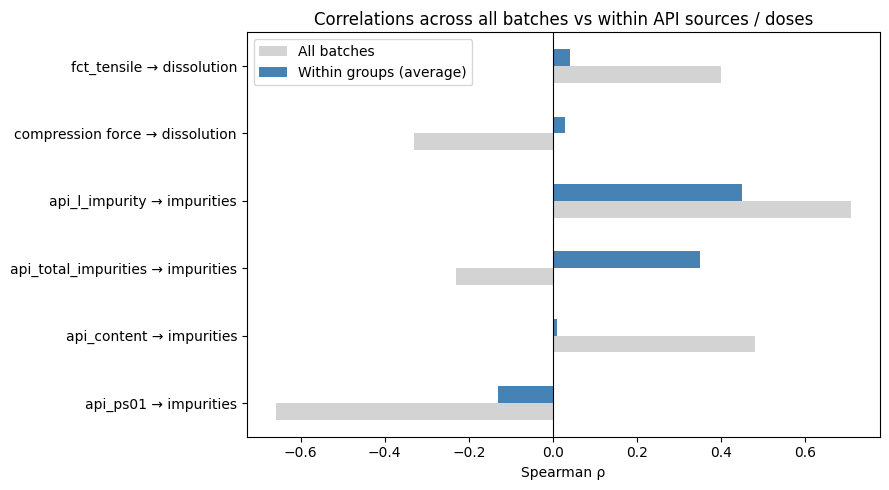

In [48]:
# Before vs after: correlation across all batches vs average within groups
comparison = pd.DataFrame({
    'All batches': [-0.66, 0.48, -0.23, 0.71, -0.33, 0.40],
    'Within groups (average)': [-0.13, 0.01, 0.35, 0.45, 0.03, 0.04]
}, index=['api_ps01 → impurities', 'api_content → impurities', 'api_total_impurities → impurities',
          'api_l_impurity → impurities', 'compression force → dissolution', 'fct_tensile → dissolution'])

comparison.plot(kind='barh', figsize=(9, 5), color=['lightgray', 'steelblue'])
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Spearman ρ')
plt.title('Correlations across all batches vs within API sources / doses')
plt.tight_layout()
plt.savefig(f'{FIGURES}/q4_before_after_correlations.png', dpi=150, bbox_inches='tight')
plt.show()

**Recommendations:**

1. **Monitor impurities by API supplier.** API source 5 consistently produces tablets with 3–5 times more total impurities (~0.26% vs ~0.07–0.11%). The Quality department should review this supplier's specifications with the Purchasing department and track impurity trends separately for each supplier. *(Q1, Q2)*

2. **Control API impurities at incoming inspection.** Within each supplier, batches made with API containing more impurity L or more total impurities have more impurities in the final product (ρ = 0.32–0.56). Setting internal acceptance limits for these two API results can help anticipate high-impurity batches before production. *(Q2)*

3. **Build control charts by supplier and by dose, not for all batches together.** Mixing suppliers made impurity charts show 25–48% of batches as out of control, which disappears when charts are built per API source. Dissolution charts should be built per dose. *(Q1)*

4. **Focus dissolution monitoring on 20 mg and 40 mg.** 20 mg is the least stable dose (2.47% out of control, with level shifts over time), and 40 mg has the lowest and most variable dissolution. Special causes in 20 mg should be investigated. *(Q1)*

5. **Do not adjust compression parameters to improve dissolution.** Compression force, fill depth and tensile strength are not related to dissolution within each dose; their apparent effect came from the dose. *(Q3)*

6. **Improve data recording.** Specification limits should be available for capability analysis; impurity L should be recorded for all API batches (missing in 77% of source 3 batches); missing values should be recorded as empty cells, not blank spaces; and hardness measurements should be reviewed, since average values fall outside their min–max range in 34–48% of batches. *(Notebooks 01 and 03)*

**Limitations:**
- Correlation does not imply causation; the relationships found should be confirmed with controlled experiments or process investigation.
- Specification limits are not reported, so process capability (Ppk) and the real risk of out-of-specification batches could not be evaluated.
- Some variables have incomplete data (e.g. `api_l_impurity`), which reduces the reliability of their correlations.

## 3. Summary of findings

| # | Question | Main finding | Chart |
|---|---|---|---|
| Q1 | Process stability | Dissolution is practically in control for 5, 10 and 40 mg; 20 mg is the least stable (2.47% out of control). Impurity charts by dose showed 25–48% out of control because they mix API sources; by source, source 5 is stable but runs at ~0.26% vs ~0.07–0.11% for the others | `imr_dissolution_min_strength_20.png`, `imr_impurities_total_api_code_5.png` |
| Q2 | Raw materials vs quality | Raw materials do not explain dissolution (\|ρ\| ≤ 0.14). For impurities, only API impurity L (ρ = 0.34–0.56) and API total impurities (ρ = 0.32–0.37) hold within each source; other strong correlations only reflected the supplier (Simpson's paradox) | `q2_raw_materials_correlation.png` |
| Q3 | Compression vs quality | Compression force, fill depth and tensile strength seem related to dissolution (ρ = −0.33 to +0.40), but the relationship disappears within each dose. Fill depth vs impurities is explained by API source 5 (lower fill, higher impurities) | `q3_compression_correlation.png` |
| Q4 | Variables to monitor | High priority: API source, API impurity L and dose. Not recommended: API particle size, compression parameters and excipients, since their effects disappear within groups | `q4_before_after_correlations.png` |